In [ ]:
!pip install --upgrade google-cloud-storage pandas scikit-learn gcsfs

In [ ]:
import os
import pandas as pd
from sklearn.model_selection import train_test_split
from google.cloud import storage

from google.colab import auth
auth.authenticate_user()

In [ ]:
PROJECT_ID = "project-2a282f15-18ae-4b89-a5f"
BUCKET_NAME = "conor-weekes-data-20084449"
LOCATION = "EU"

In [ ]:
client = storage.Client(project=PROJECT_ID)

print("Files in bucket:")

for blob in client.list_blobs(BUCKET_NAME):
    print(blob.name)

Files in bucket:
milestone2/processed/dev_processed.csv
milestone2/processed/test_processed.csv
milestone2/processed/train_processed.csv
processed/
raw/
raw/MutualFunds.csv
sharded/cv_folds/fold_0_train.csv
sharded/cv_folds/fold_0_val.csv
sharded/cv_folds/fold_1_train.csv
sharded/cv_folds/fold_1_val.csv
sharded/cv_folds/fold_2_train.csv
sharded/cv_folds/fold_2_val.csv
sharded/cv_folds/fold_3_train.csv
sharded/cv_folds/fold_3_val.csv
sharded/cv_folds/fold_4_train.csv
sharded/cv_folds/fold_4_val.csv
sharded/cv_folds/fold_5_train.csv
sharded/cv_folds/fold_5_val.csv
sharded/cv_folds/fold_6_train.csv
sharded/cv_folds/fold_6_val.csv
sharded/cv_folds/fold_7_train.csv
sharded/cv_folds/fold_7_val.csv
sharded/dev.csv
sharded/test.csv
sharded/train.csv
titanic.csv


In [ ]:
GCS_PATH = f"gs://{BUCKET_NAME}/raw/MutualFunds.csv"

df = pd.read_csv(GCS_PATH)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (23783, 298)


,fund_symbol,quote_type,region,fund_short_name,fund_long_name,currency,initial_investment,subsequent_investment,fund_category,fund_family,...,peer_environment_avg,peer_environment_max,social_score,peer_social_min,peer_social_avg,peer_social_max,governance_score,peer_governance_min,peer_governance_avg,peer_governance_max
0,AAAAX,MutualFund,US,DWS RREEF Real Assets Fund - Cl,DWS RREEF Real Assets Fund - Class A,USD,1000.0,50.0,World Allocation,DWS,...,5.05,10.58,7.43,5.98,9.07,11.30,5.43,4.26,7.14,8.11
1,AAAEX,MutualFund,US,AllianzGI Health Sciences Fund,Virtus AllianzGI Health Sciences Fund Class P,USD,1000000.0,NaN,Health,Virtus,...,1.43,3.27,12.96,9.52,12.87,15.08,8.40,4.96,7.68,10.30
2,AAAFX,MutualFund,US,NaN,American Century One Choice Blend+ 2015 Portfo...,USD,2500.0,50.0,Target-Date 2015,American Century Investments,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,AAAGX,MutualFund,US,Thrivent Large Cap Growth Fund,Thrivent Large Cap Growth Fund Class A,USD,2000.0,50.0,Large Growth,Thrivent Funds,...,2.70,5.81,10.13,7.25,10.14,11.97,8.03,5.30,7.54,8.90
4,AAAHX,MutualFund,US,NaN,American Century One Choice Blend+ 2015 Portfo...,USD,5000000.0,NaN,Target-Date 2015,American Century Investments,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


The following 4 checks were completed to access if this dataset could be used for the project but I thought it would be useful to leave these lines in to see how I came to my conclusion even if they are not necessary to reproduce the processed data set.


In [ ]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
for col in df.columns:
    print(col)

Number of rows: 23783
Number of columns: 298

Column names:
fund_symbol
quote_type
region
fund_short_name
fund_long_name
currency
initial_investment
subsequent_investment
fund_category
fund_family
exchange_code
exchange_name
exchange_timezone
management_name
management_bio
management_start_date
total_net_assets
year_to_date_return
day50_moving_average
day200_moving_average
week52_high_low_change
week52_high_low_change_perc
week52_high
week52_high_change
week52_high_change_perc
week52_low
week52_low_change
week52_low_change_perc
investment_strategy
fund_yield
morningstar_overall_rating
morningstar_risk_rating
inception_date
last_dividend
last_cap_gain
annual_holdings_turnover
investment_type
size_type
fund_annual_report_net_expense_ratio
category_annual_report_net_expense_ratio
fund_prospectus_net_expense_ratio
fund_prospectus_gross_expense_ratio
fund_max_12b1_fee
fund_max_front_end_sales_load
category_max_front_end_sales_load
fund_max_deferred_sales_load
category_max_deferred_sales_loa

In [ ]:
print("Duplicate rows:", df.duplicated().sum())

missing = df.isnull().mean().sort_values(ascending=False)

print("\nColumns with the most missing data:")
display(missing.head(20))

Duplicate rows: 0

Columns with the most missing data:


,0
last_cap_gain,0.999706
fund_return_2021_q3,0.997393
fund_max_deferred_sales_load,0.873733
fund_return_2021_q2,0.847917
fund_max_front_end_sales_load,0.844721
fund_return_2000_q4,0.833663
fund_return_2000,0.833663
fund_return_2000_q3,0.829752
fund_return_2000_q2,0.824076
fund_return_2000_q1,0.818316


In [ ]:
print("Fund category values:")
print(df["fund_category"].value_counts().head(20))

print("\nNumber of different fund categories:")
print(df["fund_category"].nunique())

print("\nMissing fund categories:")
print(df["fund_category"].isnull().sum())

Fund category values:
fund_category
Large Blend                      1235
Large Growth                     1172
Large Value                      1080
Diversified Emerging Mkts         741
Foreign Large Blend               680
Allocation--50% to 70% Equity     658
High Yield Bond                   629
Small Blend                       579
Small Growth                      578
Short-Term Bond                   570
Intermediate Core-Plus Bond       566
Mid-Cap Growth                    562
Allocation--30% to 50% Equity     491
World Allocation                  448
Foreign Large Growth              431
Intermediate Core Bond            413
Small Value                       409
Mid-Cap Value                     368
Multisector Bond                  351
Nontraditional Bond               342
Name: count, dtype: int64

Number of different fund categories:
119

Missing fund categories:
663


In [ ]:
category_counts = df["fund_category"].value_counts()

print("Smallest categories:")
display(category_counts.tail(20))

print("Categories with fewer than 10 funds:")
print((category_counts < 10).sum())

Smallest categories:


,count
fund_category,
Long Government,23
Relative Value Arbitrage,20
Japan Stock,19
Consumer Cyclical,19
Latin America Stock,17
Industrials,17
Trading--Inverse Debt,14
Consumer Defensive,12
India Equity,11


Categories with fewer than 10 funds:
11


In [ ]:
# Remove rows where fund_category is missing
df_clean = df.dropna(subset=["fund_category"]).copy()

# Count each category
category_counts = df_clean["fund_category"].value_counts()

# Keep categories with at least 10 funds
valid_categories = category_counts[category_counts >= 10].index

df_clean = df_clean[
    df_clean["fund_category"].isin(valid_categories)
].copy()

print("Rows remaining:", len(df_clean))
print("Categories remaining:", df_clean["fund_category"].nunique())



Rows remaining: 23069
Categories remaining: 108


In [ ]:
# Milestone 2 - Schema audit

schema_audit = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "missing": df.isna().sum(),
    "unique": df.nunique(dropna=True)
}).sort_values("missing", ascending=False)

display(schema_audit.head(20))

,dtype,non_null,missing,unique
last_cap_gain,float64,7,23776,3
fund_return_2021_q3,float64,62,23721,61
fund_max_deferred_sales_load,float64,3003,20780,10
fund_return_2021_q2,float64,3617,20166,2973
fund_max_front_end_sales_load,float64,3693,20090,23
fund_return_2000_q4,float64,3956,19827,3530
fund_return_2000,float64,3956,19827,3721
fund_return_2000_q3,float64,4049,19734,3389
fund_return_2000_q2,float64,4184,19599,3395
fund_return_2000_q1,float64,4321,19462,3637


In [ ]:

# Milestone 2 - Numerical summary of target variable

target = df_clean["fund_return_2021_q1"]
observed = target.dropna()

q1, q3 = observed.quantile([0.25, 0.75])

target_profile = pd.Series({
    "n": observed.size,
    "missing": target.isna().sum(),
    "mean": observed.mean(),
    "median": observed.median(),
    "std": observed.std(),
    "IQR": q3 - q1,
    "min": observed.min(),
    "max": observed.max(),
    "skew": observed.skew()
})

display(target_profile)


,0
n,22628.000000
missing,441.000000
mean,0.037400
median,0.025100
std,0.060493
IQR,0.060933
min,-0.263210
max,0.605420
skew,1.487333


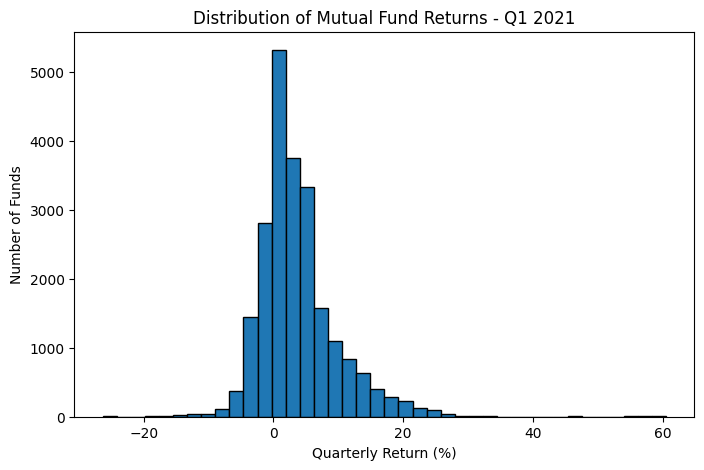

In [ ]:

# Milestone 2 - Distribution of Q1 2021 fund returns

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(observed * 100, bins=40, edgecolor="black")

plt.title("Distribution of Mutual Fund Returns - Q1 2021")
plt.xlabel("Quarterly Return (%)")
plt.ylabel("Number of Funds")

plt.show()


In [ ]:

# Milestone 2 - Identify potential outliers using IQR

iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers = observed[
    (observed < lower_bound) |
    (observed > upper_bound)
]

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Number of potential outliers:", len(outliers))
print("Percentage of observations:", round(len(outliers) / len(observed) * 100, 2))


Lower bound: -0.09174875
Upper bound: 0.15198125
Number of potential outliers: 1315
Percentage of observations: 5.81


In [ ]:

# Milestone 2 - Data quality validation

# Check missing values in important columns
important_columns = [
    "fund_symbol",
    "fund_category",
    "fund_return_2021_q1"
]

print("Missing values:")
print(df_clean[important_columns].isna().sum())

# Check for duplicate fund identifiers
print("\nDuplicate fund symbols:",
      df_clean["fund_symbol"].duplicated().sum())

# Check that the target is numerical
print("\nTarget is numeric:",
      pd.api.types.is_numeric_dtype(
          df_clean["fund_return_2021_q1"]
      ))


Missing values:
fund_symbol              0
fund_category            0
fund_return_2021_q1    441
dtype: int64

Duplicate fund symbols: 0

Target is numeric: True


In [ ]:

# Milestone 2 - Handle missing target values

target_column = "fund_return_2021_q1"

df_model = df_clean.dropna(subset=[target_column]).copy()

print("Rows before:", len(df_clean))
print("Rows after:", len(df_model))
print("Rows removed:", len(df_clean) - len(df_model))
print("Missing target values:", df_model[target_column].isna().sum())


Rows before: 23069
Rows after: 22628
Rows removed: 441
Missing target values: 0


In [ ]:
# Sources Used:
# https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.dropna.html
# https://pandas.pydata.org/docs/reference/api/pandas.Series.value_counts.html
# https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.isin.html



In [ ]:
train_df, temp_df = train_test_split(
    df_clean,
    test_size=0.20,
    random_state=42,
    stratify=df_clean["fund_category"]
)

dev_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["fund_category"]
)

print("Train:", len(train_df))
print("Dev:", len(dev_df))
print("Test:", len(test_df))

Train: 18455
Dev: 2307
Test: 2307


In [ ]:

# Milestone 2 - Prepare existing splits for regression

target_column = "fund_return_2021_q1"

train_model = train_df.dropna(subset=[target_column]).copy()
dev_model = dev_df.dropna(subset=[target_column]).copy()
test_model = test_df.dropna(subset=[target_column]).copy()

print("Training rows:", len(train_model))
print("Development rows:", len(dev_model))
print("Testing rows:", len(test_model))

print("Total rows:", len(train_model) + len(dev_model) + len(test_model))


Training rows: 18107
Development rows: 2265
Testing rows: 2256
Total rows: 22628


In [ ]:

# Milestone 2 - Check for potential temporal data leakage

print("Columns referencing 2021:")
for col in df_model.columns:
    if "2021" in col:
        print(col)

print("\nColumns referencing 2020:")
for col in df_model.columns:
    if "2020" in col:
        print(col)


Columns referencing 2021:
fund_return_2021_q3
fund_return_2021_q2
fund_return_2021_q1

Columns referencing 2020:
fund_return_2020
category_return_2020
fund_return_2020_q4
fund_return_2020_q3
fund_return_2020_q2
fund_return_2020_q1


In [ ]:

# Milestone 2 - Check historical return availability

historical_columns = [
    "fund_return_2017",
    "fund_return_2018",
    "fund_return_2019"
]

print("Missing historical returns:")
display(df_model[historical_columns].isna().sum())

print("\nPercentage available:")
display((df_model[historical_columns].notna().mean() * 100).round(2))


Missing historical returns:


,0
fund_return_2017,4067
fund_return_2018,2700
fund_return_2019,1571



Percentage available:


,0
fund_return_2017,82.03
fund_return_2018,88.07
fund_return_2019,93.06


In [ ]:

# Milestone 2 - Check 2020 return availability

print("Missing 2020 returns:")
print(df_model["fund_return_2020"].isna().sum())

print("\nPercentage available:")
print(round(df_model["fund_return_2020"].notna().mean() * 100, 2))


Missing 2020 returns:
825

Percentage available:
96.35


In [ ]:

# Milestone 2 - Select the initial features and target

feature_columns = [
    "fund_return_2017",
    "fund_return_2018",
    "fund_return_2019"
]

X_train = train_model[feature_columns]
y_train = train_model[target_column]

X_dev = dev_model[feature_columns]
y_dev = dev_model[target_column]

X_test = test_model[feature_columns]
y_test = test_model[target_column]

print("Training features:", X_train.shape)
print("Development features:", X_dev.shape)
print("Testing features:", X_test.shape)


Training features: (18107, 3)
Development features: (2265, 3)
Testing features: (2256, 3)


In [ ]:

# Milestone 2 - Preprocess historical returns

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

preprocess = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler())
])

# Learn preprocessing values
X_train_ready = preprocess.fit_transform(X_train)
X_dev_ready = preprocess.transform(X_dev)
X_test_ready = preprocess.transform(X_test)

print("Training:", X_train_ready.shape)
print("Development:", X_dev_ready.shape)
print("Testing:", X_test_ready.shape)

print("Missing values after preprocessing:",
      pd.isna(X_train_ready).sum())


Training: (18107, 3)
Development: (2265, 3)
Testing: (2256, 3)
Missing values after preprocessing: 0


In [ ]:

# Milestone 2 - Validate preprocessing results
print("Missing values in training:", pd.isna(X_train_ready).sum())
print("Missing values in development:", pd.isna(X_dev_ready).sum())
print("Missing values in testing:", pd.isna(X_test_ready).sum())



In [ ]:

# Milestone 2 - Validate train, development and test separation
train_ids = set(train_model["fund_symbol"])
dev_ids = set(dev_model["fund_symbol"])
test_ids = set(test_model["fund_symbol"])

print("Train and development overlap:", len(train_ids & dev_ids))
print("Train and test overlap:", len(train_ids & test_ids))
print("Development and test overlap:", len(dev_ids & test_ids))


In [ ]:

# Milestone 2 - Save processed datasets locally

import os

os.makedirs("milestone2_outputs", exist_ok=True)

datasets = {
    "train": (train_model, X_train_ready),
    "dev": (dev_model, X_dev_ready),
    "test": (test_model, X_test_ready)
}

for name, (original, processed) in datasets.items():
    output = pd.DataFrame(
        processed,
        columns=feature_columns,
        index=original.index
    )

    output["fund_symbol"] = original["fund_symbol"]
    output[target_column] = original[target_column]

    output.to_csv(
        f"milestone2_outputs/{name}_processed.csv",
        index=False
    )

    print(name, output.shape)


train (18107, 5)
dev (2265, 5)
test (2256, 5)


In [ ]:

# Milestone 2 - Verify saved processed files

for name in ["train", "dev", "test"]:
    path = f"milestone2_outputs/{name}_processed.csv"

    saved_df = pd.read_csv(path)

    print(name, saved_df.shape)
    print("Missing values:", saved_df.isna().sum().sum())


train (18107, 5)
Missing values: 0
dev (2265, 5)
Missing values: 0
test (2256, 5)
Missing values: 0


In [ ]:

# Milestone 2 - Upload processed datasets to Google Cloud Storage

from google.cloud import storage

client = storage.Client(project=PROJECT_ID)
bucket = client.bucket(BUCKET_NAME)

files = [
    "train_processed.csv",
    "dev_processed.csv",
    "test_processed.csv"
]

for filename in files:
    local_path = f"milestone2_outputs/{filename}"
    gcs_path = f"milestone2/processed/{filename}"

    blob = bucket.blob(gcs_path)

    if blob.exists():
        print("Already exists, skipped:", gcs_path)
    else:
        blob.upload_from_filename(
            local_path,
            if_generation_match=0
        )
        print("Uploaded:", gcs_path)


Already exists, skipped: milestone2/processed/train_processed.csv
Already exists, skipped: milestone2/processed/dev_processed.csv
Already exists, skipped: milestone2/processed/test_processed.csv


In [ ]:

# Milestone 2 - Document missing value replacements (Used instead of adding an extra column)

imputation_audit = pd.DataFrame({
    "Feature": feature_columns,
    "Training missing filled": X_train.isna().sum().values,
    "Development missing filled": X_dev.isna().sum().values,
    "Testing missing filled": X_test.isna().sum().values,
    "Replacement median": preprocess.named_steps["impute"].statistics_
})

imputation_audit["Total replaced"] = (
    imputation_audit["Training missing filled"]
    + imputation_audit["Development missing filled"]
    + imputation_audit["Testing missing filled"]
)

display(imputation_audit)


,Feature,Training missing filled,Development missing filled,Testing missing filled,Replacement median,Total replaced
0,fund_return_2017,3240,429,398,0.14006,4067
1,fund_return_2018,2131,296,273,-0.05369,2700
2,fund_return_2019,1242,171,158,0.20198,1571


In [ ]:

# Milestone 2 - Verify processed files in Google Cloud Storage

for name in ["train", "dev", "test"]:
    path = f"gs://{BUCKET_NAME}/milestone2/processed/{name}_processed.csv"

    cloud_df = pd.read_csv(path)

    print(name, cloud_df.shape)
    print("Missing values:", cloud_df.isna().sum().sum())


train (18107, 5)
Missing values: 0
dev (2265, 5)
Missing values: 0
test (2256, 5)
Missing values: 0


#Source Used:
#https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html

In [ ]:
distribution = pd.DataFrame({
    "train": train_df["fund_category"].value_counts(normalize=True),
    "dev": dev_df["fund_category"].value_counts(normalize=True),
    "test": test_df["fund_category"].value_counts(normalize=True)
})

display(distribution.head(20))

,train,dev,test
fund_category,,,
Allocation--15% to 30% Equity,0.007911,0.007802,0.007802
Allocation--30% to 50% Equity,0.021295,0.021240,0.021240
Allocation--50% to 70% Equity,0.028502,0.028609,0.028609
Allocation--70% to 85% Equity,0.012246,0.012137,0.012137
Allocation--85%+ Equity,0.006773,0.006935,0.006502
Bank Loan,0.009862,0.009970,0.009970
China Region,0.003576,0.003468,0.003468
Commodities Broad Basket,0.003847,0.003901,0.003901
Communications,0.001355,0.001300,0.001300


#Source Used:
#https://pandas.pydata.org/docs/reference/api/pandas.Series.value_counts.html

In [ ]:
from sklearn.model_selection import train_test_split, StratifiedKFold

skf = StratifiedKFold(
    n_splits=8,
    shuffle=True,
    random_state=42
)

cv_folds = {}

for fold_idx, (train_idx, val_idx) in enumerate(
    skf.split(train_df, train_df["fund_category"])
):
    cv_folds[fold_idx] = (
        train_df.iloc[train_idx].copy(),
        train_df.iloc[val_idx].copy()
    )

print("Number of CV folds:", len(cv_folds))

Number of CV folds: 8


#https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html

In [ ]:
import os

os.makedirs("shards/cv_folds", exist_ok=True)

# Save train, dev and test
train_df.to_csv("shards/train.csv", index=False)
dev_df.to_csv("shards/dev.csv", index=False)
test_df.to_csv("shards/test.csv", index=False)

# Save the 8 cross-validation folds
for fold_idx, (f_train, f_val) in cv_folds.items():
    f_train.to_csv(f"shards/cv_folds/fold_{fold_idx}_train.csv", index=False)
    f_val.to_csv(f"shards/cv_folds/fold_{fold_idx}_val.csv", index=False)

print("All shard files saved locally.")

All shard files saved locally.


In [ ]:
# def upload_folder_to_gcs(local_folder, bucket_name, gcs_prefix):
    # client = storage.Client(project=PROJECT_ID)
    # bucket = client.bucket(bucket_name)

    # for root, _, files in os.walk(local_folder):
        # for file in files:
           # local_path = os.path.join(root, file)

           # relative_path = os.path.relpath(
                #local_path,
               # local_folder
           # )

           # gcs_path = os.path.join(
               # gcs_prefix,
               # relative_path
           # ).replace("\\", "/")

           # blob = bucket.blob(gcs_path)
           # blob.upload_from_filename(local_path)

           # print("Uploaded:", gcs_path)


#upload_folder_to_gcs(
    #"shards",
   # BUCKET_NAME,
    #"sharded"
#)

Uploaded: sharded/dev.csv
Uploaded: sharded/test.csv
Uploaded: sharded/train.csv
Uploaded: sharded/cv_folds/fold_5_val.csv
Uploaded: sharded/cv_folds/fold_7_train.csv
Uploaded: sharded/cv_folds/fold_4_val.csv
Uploaded: sharded/cv_folds/fold_0_train.csv
Uploaded: sharded/cv_folds/fold_3_val.csv
Uploaded: sharded/cv_folds/fold_3_train.csv
Uploaded: sharded/cv_folds/fold_6_train.csv
Uploaded: sharded/cv_folds/fold_0_val.csv
Uploaded: sharded/cv_folds/fold_4_train.csv
Uploaded: sharded/cv_folds/fold_2_train.csv
Uploaded: sharded/cv_folds/fold_1_train.csv
Uploaded: sharded/cv_folds/fold_5_train.csv
Uploaded: sharded/cv_folds/fold_2_val.csv
Uploaded: sharded/cv_folds/fold_6_val.csv
Uploaded: sharded/cv_folds/fold_7_val.csv
Uploaded: sharded/cv_folds/fold_1_val.csv


#Source Used:
#https://docs.python.org/3/library/os.html
